<a href="https://colab.research.google.com/github/rojaktukimin/Sleep-Analysis---Student/blob/main/Sleep_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import (
    wilcoxon,
    kruskal,
    spearmanr
)

sns.set_theme(style="whitegrid")

In [11]:
df = pd.read_excel(
    "/content/Survei Pengaruh Kualitas Tidur Terhadap Konsentrasi Belajar Mahasiswa (Jawaban).xlsx"
)

print(df.shape)
df.info()
df.head()

(106, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 106 entries, 0 to 105
Data columns (total 13 columns):
 #   Column                                                                                               Non-Null Count  Dtype         
---  ------                                                                                               --------------  -----         
 0   Timestamp                                                                                            106 non-null    datetime64[ns]
 1   Kelas PPKU 
(Contoh Format Penulisan Kelas : ST26)                                                   106 non-null    object        
 2   Jenis Kelamin                                                                                        106 non-null    object        
 3   Pukul berapa biasanya Anda tidur pada hari weekdays?                                                 106 non-null    object        
 4   Pukul berapa biasanya Anda tidur pada hari weekend?       

,Timestamp,Kelas PPKU \n(Contoh Format Penulisan Kelas : ST26),Jenis Kelamin,Pukul berapa biasanya Anda tidur pada hari weekdays?,Pukul berapa biasanya Anda tidur pada hari weekend?,Berapa lama Anda tidur pada hari weekdays?,Berapa lama Anda tidur pada hari weekend?,Seberapa berkualitas tidur Anda pada weekdays?,Seberapa berkualitas tidur Anda pada weekend?,Hal apa yang biasanya mempengaruhi jam tidur Anda? (Anda boleh memilih lebih dari satu),"Menurut Anda, apakah waktu tidur Anda mempengaruhi tingkat konsentrasi dalam mengikuti perkuliahan?","Jika iya, hal manakah yang pernah Anda rasakan di saat perkuliahan berlangsung?",Apakah Mata Kuliah yang terlalu pagi mempengaruhi jam tidur dan kualitas tidur Anda?
0,2022-11-25 09:31:41.617,INT ST01,Perempuan,23.00-23.59,21.00-22.59,>7 jam,>7 jam,5,3,"Belajar, Sosial Media, Overthinking",Iya,"Melamun, Mengantuk, Kepala pusing, Kesulitan m...",Tidak
1,2022-11-21 13:46:39.441,SS07,Perempuan,21.00-22.59,23.00-23.59,>7 jam,>7 jam,5,5,Sosial Media,Iya,"Mengantuk, Kepala pusing, Kesulitan memahami m...",Iya
2,2022-11-21 13:52:43.306,SS10,Perempuan,<21.00,<21.00,>7 jam,>7 jam,5,5,"Belajar, Menonton, Sosial Media, Overthingking",Iya,Mengantuk,Tidak
3,2022-11-16 19:58:24.389,ST03,Laki-laki,>00.00,>00.00,>7 jam,>7 jam,3,3,"Game, Nongkrong",Iya,"Melamun, Mengantuk, Kesulitan memahami materi ...",Iya
4,2022-11-16 18:19:59.190,ST22,Perempuan,21.00-22.59,21.00-22.59,>7 jam,>7 jam,4,4,"Belajar, Menonton, Sosial Media, Overthingking",Iya,"Mengantuk, Kepala pusing, Kesulitan memahami m...",Iya


In [12]:
# Remove personal identifiers
df = df.drop(
    columns=["Email", "Nama "],
    errors="ignore"
)

# Check missing values
print(df.isnull().sum())

# Check duplicate records
print(df.duplicated().sum())

Timestamp                                                                                              0
Kelas PPKU \n(Contoh Format Penulisan Kelas : ST26)                                                    0
Jenis Kelamin                                                                                          0
Pukul berapa biasanya Anda tidur pada hari weekdays?                                                   0
Pukul berapa biasanya Anda tidur pada hari weekend?                                                    0
Berapa lama Anda tidur pada hari weekdays?                                                             0
Berapa lama Anda tidur pada hari weekend?                                                              0
Seberapa berkualitas tidur Anda pada weekdays?                                                         0
Seberapa berkualitas tidur Anda pada weekend?                                                          0
Hal apa yang biasanya mempengaruhi jam tidur Anda? (And

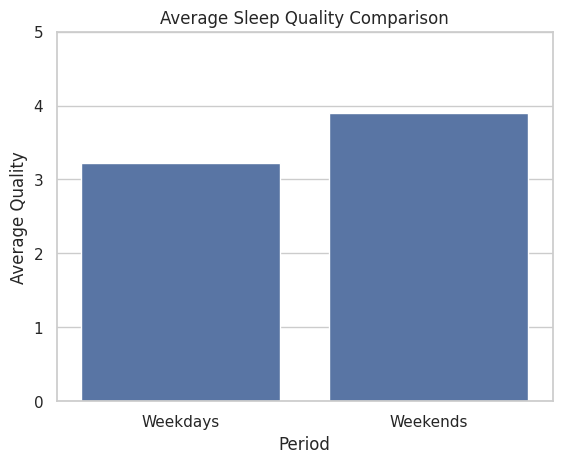

In [13]:
sleep_quality = pd.DataFrame({
    "Period": ["Weekdays", "Weekends"],
    "Average Quality": [
        df[
            "Seberapa berkualitas tidur Anda pada weekdays?"
        ].mean(),

        df[
            "Seberapa berkualitas tidur Anda pada weekend?"
        ].mean()
    ]
})

sns.barplot(
    data=sleep_quality,
    x="Period",
    y="Average Quality"
)

plt.title("Average Sleep Quality Comparison")
plt.ylim(0, 5)
plt.show()

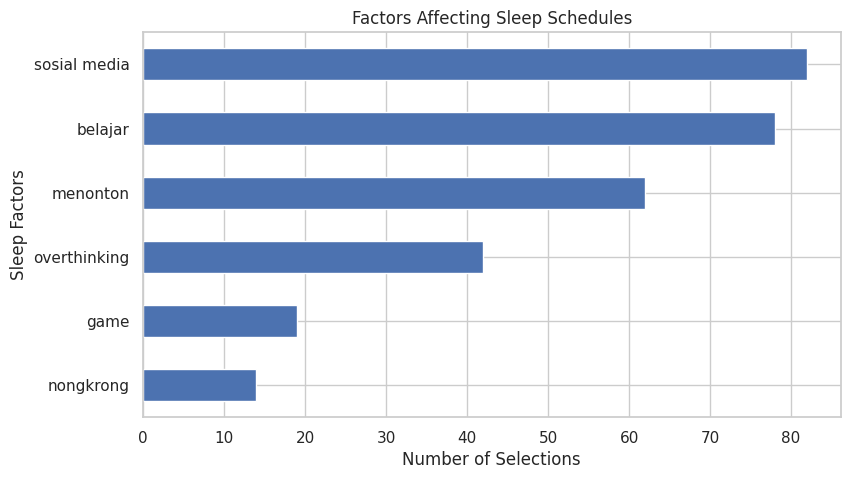

In [14]:
column = (
    "Hal apa yang biasanya mempengaruhi "
    "jam tidur Anda? (Anda boleh memilih lebih dari satu)"
)

factors = (
    df[column]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
    .str.lower()
)

factors = factors.replace({
    "overthingking": "overthinking"
})

factor_counts = factors.value_counts()

factor_counts.plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Factors Affecting Sleep Schedules")
plt.xlabel("Number of Selections")
plt.ylabel("Sleep Factors")
plt.gca().invert_yaxis()
plt.show()

In [15]:
duration_column = (
    "Berapa lama Anda tidur pada hari weekdays?"
)

quality_column = (
    "Seberapa berkualitas tidur Anda pada weekdays?"
)

sleep_analysis = (
    df.groupby(duration_column)[quality_column]
    .agg(["count", "mean", "median"])
)

print(sleep_analysis)

                                            count      mean  median
Berapa lama Anda tidur pada hari weekdays?                         
1-3 jam                                         6  2.833333     3.0
4-6 jam                                        84  3.071429     3.0
>7 jam                                         16  4.187500     4.5


In [16]:
groups = [
    group[quality_column].values
    for _, group in df.groupby(duration_column)
]

stat, p_value = kruskal(*groups)

print("Statistic:", stat)
print("P-value:", p_value)

Statistic: 17.63839233384125
P-value: 0.0001478671729978297


In [17]:
stat, p_value = wilcoxon(
    df[
        "Seberapa berkualitas tidur Anda pada weekdays?"
    ],
    df[
        "Seberapa berkualitas tidur Anda pada weekend?"
    ]
)

print("Statistic:", stat)
print("P-value:", p_value)

Statistic: 167.0
P-value: 6.806202951126911e-09
